# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Đọc `README.md` và `GUIDE.md` trước. Notebook này cung cấp đầy đủ các bước thực hiện theo hướng dẫn và cấu hình trong thư mục `configs/`.


## 0. Môi trường (Colab T4 / Kaggle GPU)
Kiểm tra GPU (khuyên dùng GPU T4 x1 hoặc P100 trên Kaggle), clone repository mã nguồn và cài đặt thư viện. Khi import notebook trực tiếp vào Kaggle, hãy bật **Internet** để clone repo, cài package và tải model từ Hugging Face.


In [1]:
# 1. Thiết lập thư mục làm việc và tải toàn bộ mã nguồn bài lab
import os
import subprocess
from pathlib import Path

# Nếu chạy trên Kaggle, đảm bảo đang ở thư mục /kaggle/working
if Path("/kaggle/working").exists():
    os.chdir("/kaggle/working")

workspace_dir = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
repo_dir = workspace_dir / "K4-Track-4-Day10-VisionLanguageModel"
if not Path("scripts/prepare_data.py").exists() or not Path("configs/e1.yaml").exists():
    if not repo_dir.exists():
        subprocess.run([
            "git", "clone",
            "https://github.com/ductrieunguyen897-code/K4-Track-4-Day10-VisionLanguageModel.git",
            str(repo_dir),
        ], check=True)
    if (repo_dir / "scripts/prepare_data.py").exists():
        os.chdir(repo_dir)
        print(f"Thư mục làm việc: {Path.cwd()}")

assert Path("requirements-colab.txt").exists(), "Không tìm thấy repository của bài lab. Hãy bật Internet trên Kaggle."

# 2. Kiểm tra GPU và cài đặt thư viện
!nvidia-smi -L
!pip -q install -r requirements-colab.txt pytest matplotlib
# Kaggle cài sẵn torchao 0.10.0, không tương thích với PEFT 0.21.2.
# Lab dùng bitsandbytes NF4, không dùng torchao, nên gỡ backend tùy chọn này.
!pip -q uninstall -y torchao

# Fail fast trước khi tải model nhiều GB.
import importlib.metadata as package_metadata
import importlib.util
expected_versions = {
    "transformers": "5.19.0", "peft": "0.21.2",
    "accelerate": "1.15.0", "bitsandbytes": "0.50.2",
}
for package, expected in expected_versions.items():
    actual = package_metadata.version(package)
    assert actual == expected, f"{package}={actual}, kỳ vọng {expected}"
assert importlib.util.find_spec("torchao") is None, (
    "torchao cũ vẫn còn trong môi trường; restart session rồi chạy lại cell này."
)
print("✓ Phiên bản thư viện đúng và torchao không còn trong môi trường.")
!python -m pytest -q


Cloning into '/kaggle/working/K4-Track-4-Day10-VisionLanguageModel'...


Thư mục làm việc: /kaggle/working/K4-Track-4-Day10-VisionLanguageModel
GPU 0: Tesla T4 (UUID: GPU-0909ed50-ddc4-e755-8fcb-db877ad7cda1)
GPU 1: Tesla T4 (UUID: GPU-78b4069f-6992-a85b-904b-69e175dd4bb3)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 97.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 36.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 38.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 51.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 19.7 MB/s eta 0:00:00
✓ Phiên bản thư viện đúng và torchao không còn trong môi trường.
...........................s.........................................    [100%]
68 passed, 1 skipped in 0.39s


In [2]:
# 3. Nạp Kaggle API Key (hỗ trợ Kaggle Secrets, file .env, Colab Secrets, hoặc ~/.kaggle/kaggle.json)
import os
import getpass
from pathlib import Path

# Cách A: Thử đọc từ Kaggle Secrets (Add-ons -> Secrets trên Kaggle Notebook)
try:
    from kaggle_secrets import UserSecretsClient
    user_secrets = UserSecretsClient()
    os.environ['KAGGLE_USERNAME'] = user_secrets.get_secret("KAGGLE_USERNAME")
    os.environ['KAGGLE_KEY'] = user_secrets.get_secret("KAGGLE_KEY")
    print("✓ Đã nạp credentials từ Kaggle Secrets.")
except Exception:
    pass

# Cách B: Đọc từ file .env nếu có
env_file = Path(".env")
if ('KAGGLE_USERNAME' not in os.environ or 'KAGGLE_KEY' not in os.environ) and env_file.exists():
    for line in env_file.read_text(encoding="utf-8").splitlines():
        line = line.strip()
        if line and not line.startswith("#") and "=" in line:
            k, v = line.split("=", 1)
            os.environ.setdefault(k.strip(), v.strip().strip('"').strip("'"))
    if "KAGGLE_USERNAME" in os.environ and "KAGGLE_KEY" in os.environ:
        print("✓ Đã nạp credentials từ file .env.")

# Cách C: Đọc từ Colab Secrets
if 'KAGGLE_USERNAME' not in os.environ or 'KAGGLE_KEY' not in os.environ:
    try:
        from google.colab import userdata
        os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
        os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
        print("✓ Đã nạp credentials từ Colab Secrets.")
    except Exception:
        pass

# Kiểm tra file ~/.kaggle/kaggle.json
kaggle_file = Path.home() / ".kaggle" / "kaggle.json"
if os.environ.get('KAGGLE_USERNAME') and os.environ.get('KAGGLE_KEY'):
    print("✓ Kaggle API credentials đã sẵn sàng.")
elif kaggle_file.exists():
    print(f"✓ Tìm thấy file cấu hình tại: {kaggle_file}")
else:
    print("Lưu ý: Nếu chưa cấu hình Kaggle API, bạn có thể thêm dataset trực tiếp qua '+ Add Input' trên Kaggle.")


Lưu ý: Nếu chưa cấu hình Kaggle API, bạn có thể thêm dataset trực tiếp qua '+ Add Input' trên Kaggle.


## 1. Dữ liệu: tải và chia split
Tự động phát hiện dữ liệu nếu bạn đã '+ Add Input' trên Kaggle, hoặc tự động tải về qua Kaggle API.


In [3]:
# Tự động phát hiện dataset trong /kaggle/input (nếu đã Add Input) hoặc tải qua Kaggle API
from pathlib import Path

kaggle_input = Path("/kaggle/input")
dataset_source = None

if kaggle_input.exists():
    for p in kaggle_input.rglob("images"):
        if p.is_dir() and (p.parent / "labels-YOLO").is_dir():
            dataset_source = str(p.parent)
            break

if dataset_source:
    print(f"✓ Tìm thấy dataset có sẵn tại Kaggle Input: {dataset_source}")
    print("Chuẩn bị dữ liệu từ input cục bộ (siêu nhanh, không cần tải lại)...")
    !python scripts/prepare_data.py --source "{dataset_source}"
else:
    print("Tải và chuẩn bị dữ liệu bằng Kaggle CLI...")
    !python scripts/prepare_data.py --kaggle


Tải và chuẩn bị dữ liệu bằng Kaggle CLI...
Dataset URL: https://www.kaggle.com/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes
License(s): MIT
100%|████████████████████████████████████████| 185M/185M [00:04<00:00, 44.9MB/s]

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}


Tổng số ảnh: Train = 1422, Val = 276, Test = 311
Thống kê số lượng box theo lớp:
  Train: {'pothole': 1074, 'crack': 1750, 'manhole': 691}
  Val:   {'pothole': 66, 'crack': 470, 'manhole': 103}
  Test:  {'pothole': 121, 'crack': 299, 'manhole': 163}
✓ Kiểm tra split: Không có rò rỉ session giữa các split.


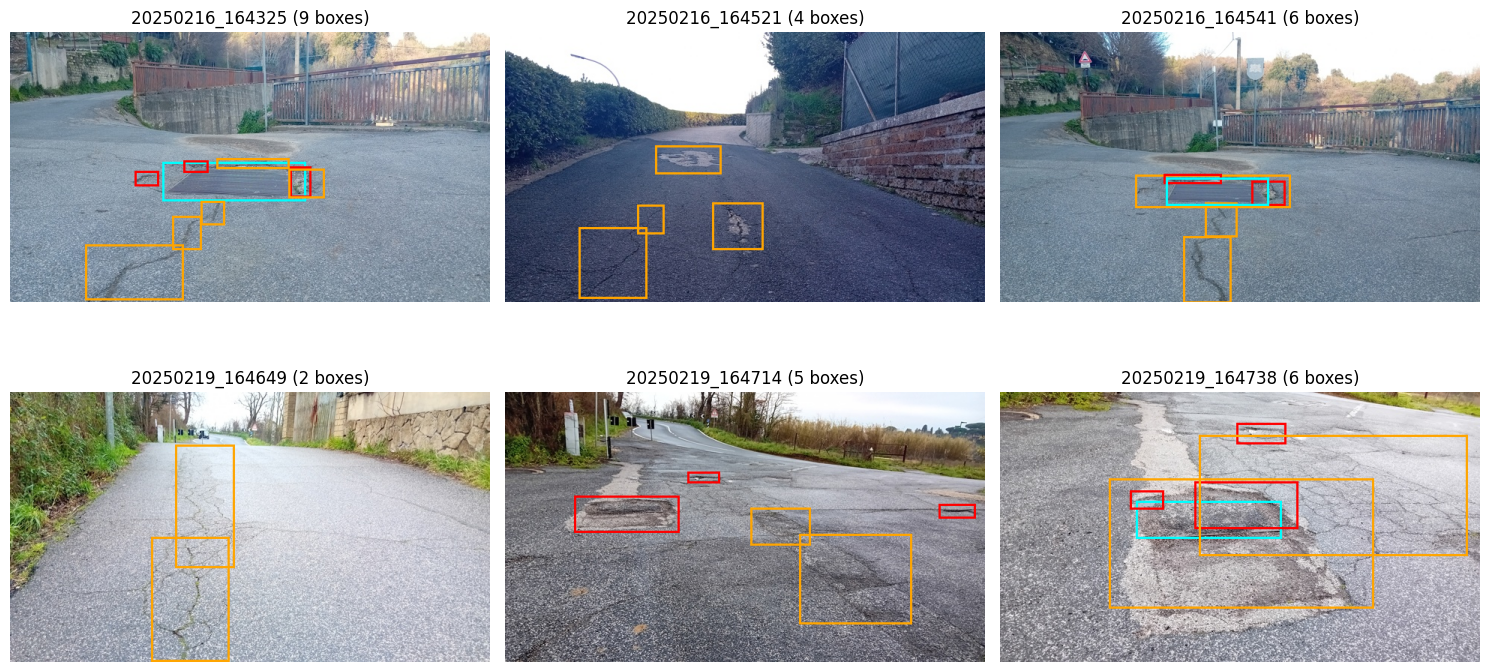

In [4]:
# Kiểm tra dữ liệu: Đọc splits, thống kê số lượng ảnh/box và trực quan hoá 6 ảnh mẫu
import json
from pathlib import Path
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
from scripts.labcommon import read_jsonl, CLASSES

train_records = read_jsonl("data/splits/train.jsonl")
val_records = read_jsonl("data/splits/val.jsonl")
test_records = read_jsonl("data/splits/test.jsonl")

print(f"Tổng số ảnh: Train = {len(train_records)}, Val = {len(val_records)}, Test = {len(test_records)}")

def count_boxes(records):
    counts = {c: 0 for c in CLASSES}
    for r in records:
        for o in r["objects"]:
            counts[o["label"]] += 1
    return counts

print("Thống kê số lượng box theo lớp:")
print("  Train:", count_boxes(train_records))
print("  Val:  ", count_boxes(val_records))
print("  Test: ", count_boxes(test_records))

# Kiểm tra phân hoạch theo session: Đảm bảo không session nào bị trùng lặp giữa các split
train_sess = {r["session"] for r in train_records}
val_sess = {r["session"] for r in val_records}
test_sess = {r["session"] for r in test_records}
assert len(train_sess & val_sess) == 0, "Rò rỉ session giữa Train và Val!"
assert len(train_sess & test_sess) == 0, "Rò rỉ session giữa Train và Test!"
assert len(val_sess & test_sess) == 0, "Rò rỉ session giữa Val và Test!"
print("✓ Kiểm tra split: Không có rò rỉ session giữa các split.")

# Trực quan hoá 6 ảnh mẫu kèm nhãn bounding box
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
colors = {"pothole": "red", "crack": "orange", "manhole": "cyan"}

samples = [r for r in train_records if len(r["objects"]) > 0][:6]
for ax, item in zip(axes.flat, samples):
    img = Image.open(Path("data") / item["image_path"]).convert("RGB")
    w, h = img.size
    draw = ImageDraw.Draw(img)
    for obj in item["objects"]:
        xc, yc, bw, bh = obj["yolo"]
        x1, y1 = (xc - bw / 2) * w, (yc - bh / 2) * h
        x2, y2 = (xc + bw / 2) * w, (yc + bh / 2) * h
        draw.rectangle([x1, y1, x2, y2], outline=colors.get(obj["label"], "white"), width=3)
    ax.imshow(img)
    ax.set_title(f"{item['image_id']} ({len(item['objects'])} boxes)")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 2. Nhãn: YOLO → JSON thang 0–1000
Chuyển đổi nhãn định dạng YOLO ([xc, yc, w, h] chuẩn hoá [0,1]) sang định dạng JSON grounding [x1, y1, x2, y2] trên thang đo nguyên 0–1000.


Prompt chuẩn:
 Locate all road damage in the image: pothole, crack, and manhole. Output a JSON list of objects with 'label' and 'bbox_2d' ([x1, y1, x2, y2] integers on a 0-1000 scale relative to width and height). Do not output any markdown formatting or extra explanation, only the JSON list.

Ví dụ câu trả lời nhãn grounding (JSON):
 [{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]


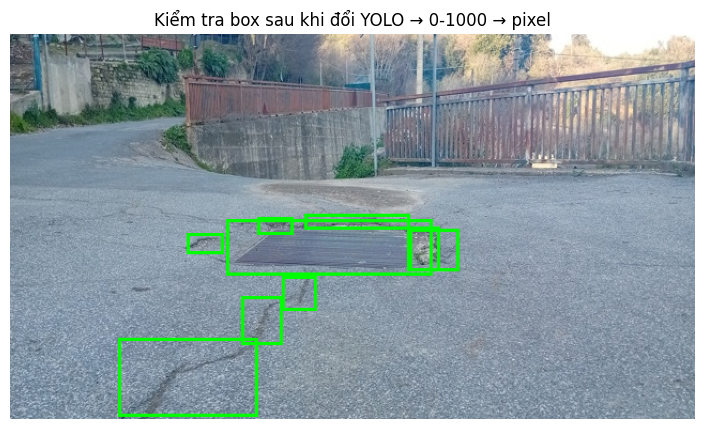

In [5]:
import json

def yolo_to_box(label: str, yolo: list) -> dict:
    """Chuyển đổi toạ độ YOLO [0, 1] sang bounding box thang 0-1000 kẹp giá trị nguyên."""
    xc, yc, w, h = yolo
    x1 = int(round(max(0.0, min(1000.0, (xc - w / 2) * 1000))))
    y1 = int(round(max(0.0, min(1000.0, (yc - h / 2) * 1000))))
    x2 = int(round(max(0.0, min(1000.0, (xc + w / 2) * 1000))))
    y2 = int(round(max(0.0, min(1000.0, (yc + h / 2) * 1000))))
    return {"label": label, "bbox_2d": [x1, y1, x2, y2]}

def objects_to_answer(objects: list) -> str:
    """Chuyển danh sách vật thể thành chuỗi JSON, sắp xếp theo (y1, x1) để ổn định khi học."""
    boxes = [yolo_to_box(o["label"], o["yolo"]) for o in objects]
    boxes.sort(key=lambda b: (b["bbox_2d"][1], b["bbox_2d"][0]))
    return json.dumps(boxes, separators=(",", ":"))

PROMPT = (
    "Locate all road damage in the image: pothole, crack, and manhole. "
    "Output a JSON list of objects with 'label' and 'bbox_2d' ([x1, y1, x2, y2] integers on a 0-1000 scale relative to width and height). "
    "Do not output any markdown formatting or extra explanation, only the JSON list."
)

# Kiểm chứng hàm chuyển đổi với mẫu đầu tiên
sample = next(r for r in train_records if r["objects"])
ans_str = objects_to_answer(sample["objects"])
print("Prompt chuẩn:\n", PROMPT)
print("\nVí dụ câu trả lời nhãn grounding (JSON):\n", ans_str)

# Quy ngược box 0-1000 về pixel để kiểm tra trực quan đúng theo GUIDE.
with Image.open(Path("data") / sample["image_path"]) as src:
    check_img = src.convert("RGB")
draw = ImageDraw.Draw(check_img)
img_w, img_h = check_img.size
for box in json.loads(ans_str):
    x1, y1, x2, y2 = box["bbox_2d"]
    draw.rectangle(
        [x1 / 1000 * img_w, y1 / 1000 * img_h, x2 / 1000 * img_w, y2 / 1000 * img_h],
        outline="lime", width=3,
    )
plt.figure(figsize=(10, 5))
plt.imshow(check_img)
plt.title("Kiểm tra box sau khi đổi YOLO → 0-1000 → pixel")
plt.axis("off")
plt.show()
check_img.close()


## 3. E0: zero-shot
Sử dụng mô hình gốc `Qwen/Qwen3-VL-4B-Instruct` chưa qua huấn luyện để suy luận trực tiếp trên tập test.


In [6]:
import torch
import bitsandbytes as bnb
from transformers import BitsAndBytesConfig, Qwen3VLForConditionalGeneration, AutoProcessor
from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm
from scripts.labcommon import read_jsonl, write_jsonl

assert torch.cuda.is_available(), "Không tìm thấy CUDA. Trên Kaggle hãy chọn Accelerator = GPU T4."
MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"

# Cấu hình lượng tử hoá 4-bit NF4, giữ ViT và lm_head ở FP16.
# Transformers 5.x so khớp skip theo prefix đầy đủ; Qwen3-VL đặt ViT tại model.visual.
BNB_SKIP_MODULES = ["model.visual", "visual", "lm_head"]
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    llm_int8_skip_modules=BNB_SKIP_MODULES,
)

def validate_quantized_model(loaded_model):
    """Xác nhận LLM là 4-bit nhưng toàn bộ vision tower vẫn ở full precision."""
    quantized = [
        name for name, module in loaded_model.named_modules()
        if isinstance(module, (bnb.nn.Linear4bit, bnb.nn.Linear8bitLt))
    ]
    quantized_visual = [name for name in quantized if "visual" in name]
    assert quantized, "Không tìm thấy layer bitsandbytes; model có thể chưa được load 4-bit."
    assert not quantized_visual, (
        "ViT bị lượng tử hoá ngoài ý muốn: " + ", ".join(quantized_visual[:8])
    )
    print(f"✓ Model có {len(quantized)} linear 4-bit; vision tower giữ FP16.")

def load_base_model():
    print(f"Đang nạp mô hình {MODEL_ID}...")
    loaded_model = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID, quantization_config=bnb_config, dtype=torch.float16, device_map={"": 0},
    )
    validate_quantized_model(loaded_model)
    return loaded_model

model = load_base_model()
processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.tokenizer.padding_side = "left"

INFERENCE_BATCH_SIZE = 4  # Nếu T4 bị OOM khi generate, giảm xuống 2

def predict_split(
    model, processor, split_path="data/splits/test.jsonl", out_path="work/e0.jsonl",
    prompt=PROMPT, batch_size=INFERENCE_BATCH_SIZE, limit=None,
):
    """Suy luận theo batch và ghi kết quả dạng JSON Lines."""
    Path(out_path).parent.mkdir(parents=True, exist_ok=True)
    records = read_jsonl(split_path)
    if limit is not None:
        records = records[:limit]
    out_rows = []
    model.eval()
    model.config.use_cache = True

    for start in tqdm(range(0, len(records), batch_size), desc=f"Inference -> {out_path}"):
        items = records[start:start + batch_size]
        images, conversations = [], []
        for item in items:
            with Image.open(Path("data") / item["image_path"]) as src:
                img = src.convert("RGB")
            images.append(img)
            conversations.append([{
                "role": "user",
                "content": [
                    {"type": "image", "image": img},
                    {"type": "text", "text": prompt},
                ],
            }])

        inputs = processor.apply_chat_template(
            conversations,
            add_generation_prompt=True,
            tokenize=True,
            return_dict=True,
            return_tensors="pt",
            padding=True,
        ).to(model.device)
        for img in images:
            img.close()

        prompt_len = inputs.input_ids.shape[1]
        # Autocast cần thiết cho E2/E3 vì projector trainable được giữ ở float32.
        with torch.inference_mode(), torch.amp.autocast("cuda", dtype=torch.float16):
            gen = model.generate(**inputs, max_new_tokens=256, do_sample=False)
        raw_batch = processor.tokenizer.batch_decode(
            gen[:, prompt_len:], skip_special_tokens=True
        )
        out_rows.extend(
            {"image_id": item["image_id"], "raw": raw.strip()}
            for item, raw in zip(items, raw_batch)
        )

    write_jsonl(out_path, out_rows)
    print(f"✓ Đã lưu kết quả suy luận vào {out_path} ({len(out_rows)} ảnh).")

# Thực hiện suy luận E0 trên tập test
predict_split(model, processor, split_path="data/splits/test.jsonl", out_path="work/e0.jsonl")


Đang nạp mô hình Qwen/Qwen3-VL-4B-Instruct...


config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

Inference -> work/e0.jsonl:   0%|          | 0/78 [00:00<?, ?it/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transform

✓ Đã lưu kết quả suy luận vào work/e0.jsonl (311 ảnh).


In [7]:
# Chấm điểm E0, sau đó giải phóng model trước khi nạp model huấn luyện E1
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json

print("\n5 output thô đầu tiên của E0:")
for row in read_jsonl("work/e0.jsonl")[:5]:
    print(row["image_id"], "->", row["raw"][:500])

import gc
del model
gc.collect()
torch.cuda.empty_cache()
print("✓ Đã giải phóng model E0 khỏi GPU.")


E0 [test] n=311 valid=0.740 P=0.146 R=0.070 F1=0.095 CI95=0.068-0.125 meanIoU=0.608 FP/img=0.77
   pothole  P=0.367 R=0.091 F1=0.146
   crack    P=0.037 R=0.020 F1=0.026
   manhole  P=0.276 R=0.147 F1=0.192

5 output thô đầu tiên của E0:
vlcsnap-00200 -> [
	{"label": "manhole", "bbox_2d": [759, 640, 843, 690], "confidence": 0.72},
	{"label": "manhole", "bbox_2d": [909, 786, 997, 824], "confidence": 0.72}
]
vlcsnap-00201 -> [

]
vlcsnap-00202 -> [
	{"label": "manhole", "bbox_2d": [309, 684, 396, 719]
}
vlcsnap-00203 -> [

]
vlcsnap-00204 -> [
	{"label": "manhole", "bbox_2d": [253, 624, 325, 657]
}
✓ Đã giải phóng model E0 khỏi GPU.


## 4. Dựng dữ liệu huấn luyện: chat template và mask loss
Chuẩn bị hàm `encode_example` và `collate_fn`. Chỉ tính loss trên phần câu trả lời của trợ lý (mask các token của prompt và ảnh bằng `-100`).


In [8]:
import torch
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

def encode_example(image, prompt, answer, processor):
    """Mã hoá một mẫu dữ liệu; gán nhãn -100 cho toàn bộ prompt và token ảnh."""
    user_msg = {
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": prompt},
        ],
    }
    asst_msg = {
        "role": "assistant",
        "content": [
            {"type": "text", "text": answer},
        ],
    }

    prompt_enc = processor.apply_chat_template(
        [user_msg],
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    )
    full_enc = processor.apply_chat_template(
        [user_msg, asst_msg],
        add_generation_prompt=False,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    )

    prompt_len = prompt_enc.input_ids.shape[1]
    assert torch.equal(full_enc.input_ids[0, :prompt_len], prompt_enc.input_ids[0]), "Prompt không phải là tiền tố!"

    labels = full_enc.input_ids.clone()
    labels[:, :prompt_len] = -100  # Chỉ tính loss trên câu trả lời
    full_enc["labels"] = labels
    return full_enc

class RoadDamageDataset(Dataset):
    def __init__(self, jsonl_path, prompt=PROMPT, img_dir="data"):
        self.records = read_jsonl(jsonl_path)
        self.prompt = prompt
        self.img_dir = Path(img_dir)

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        item = self.records[idx]
        with Image.open(self.img_dir / item["image_path"]) as src:
            img = src.convert("RGB")
        ans = objects_to_answer(item["objects"])
        return img, self.prompt, ans

def collate_fn(batch, processor):
    encoded_list = []
    for img, prompt, answer in batch:
        try:
            encoded_list.append(encode_example(img, prompt, answer, processor))
        finally:
            img.close()

    pad_id = processor.tokenizer.pad_token_id if processor.tokenizer.pad_token_id is not None else 0
    input_ids = [enc.input_ids.squeeze(0) for enc in encoded_list]
    attention_mask = [enc.attention_mask.squeeze(0) for enc in encoded_list]
    labels = [enc.labels.squeeze(0) for enc in encoded_list]

    batch_dict = {
        "input_ids": pad_sequence(input_ids, batch_first=True, padding_value=pad_id),
        "attention_mask": pad_sequence(attention_mask, batch_first=True, padding_value=0),
        "labels": pad_sequence(labels, batch_first=True, padding_value=-100),
    }

    if "mm_token_type_ids" in encoded_list[0]:
        mm_types = [enc["mm_token_type_ids"].squeeze(0) for enc in encoded_list]
        batch_dict["mm_token_type_ids"] = pad_sequence(mm_types, batch_first=True, padding_value=0)

    if "pixel_values" in encoded_list[0]:
        batch_dict["pixel_values"] = torch.cat([enc["pixel_values"] for enc in encoded_list], dim=0)
    if "image_grid_thw" in encoded_list[0]:
        batch_dict["image_grid_thw"] = torch.cat([enc["image_grid_thw"] for enc in encoded_list], dim=0)

    return batch_dict

# Kiểm tra mã hoá 1 mẫu
sample_item = train_records[0]
with Image.open(Path("data") / sample_item["image_path"]) as src:
    sample_img = src.convert("RGB")
sample_ans = objects_to_answer(sample_item["objects"])
sample_enc = encode_example(sample_img, PROMPT, sample_ans, processor)

if "image_grid_thw" in sample_enc:
    t, h, w = sample_enc.image_grid_thw[0].tolist()
    vision_tokens = (h * w) // 4
    print(f"Thống kê grid ảnh: ({t}, {h}, {w}) -> Vision tokens = {vision_tokens} (kỳ vọng: 220)")
    assert vision_tokens == 220, f"Số vision token bất thường: {vision_tokens}; kiểm tra phiên bản processor."

active_tokens = sample_enc.labels[0][sample_enc.labels[0] != -100]
print("Mục tiêu huấn luyện (sau khi giải mã):", repr(processor.tokenizer.decode(active_tokens, skip_special_tokens=False)))
sample_img.close()


Thống kê grid ảnh: (1, 22, 40) -> Vision tokens = 220 (kỳ vọng: 220)
Mục tiêu huấn luyện (sau khi giải mã): '[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]<|im_end|>\n'


## 5. Setup LoRA / đóng băng cho E1, E2, E3
- **E1**: LoRA chỉ trên LLM (`self_attn` và `mlp`: 252 modules).
- **E2**: E1 + mở toàn bộ tham số projector (`visual.merger`, `visual.deepstack_merger_list`) ở kiểu dữ liệu `float32`.
- **E3**: E2 + LoRA trên các khối attention và MLP của ViT (thêm 96 modules -> 348 modules).


In [9]:
from peft import LoraConfig, get_peft_model
import bitsandbytes as bnb
import torch

def apply_setup(base_model, setup: str, config: dict):
    """Áp dụng cấu hình đóng băng và cấu hình LoRA theo từng thí nghiệm."""
    for param in base_model.parameters():
        param.requires_grad = False
    base_model.enable_input_require_grads()

    lora_config = config.get("lora", {})
    target_kind = lora_config.get("targets", "llm")
    if target_kind == "llm":
        # LoRA LLM: 36 layers * 7 modules = 252 modules
        target_modules = r".*language_model\.layers\.\d+\.(self_attn\.(q|k|v|o)_proj|mlp\.(gate|up|down)_proj)"
    elif target_kind == "llm+vit":
        # LoRA LLM + ViT: 252 + 96 = 348 modules
        target_modules = (
            r".*(language_model\.layers\.\d+\.(self_attn\.(q|k|v|o)_proj|mlp\.(gate|up|down)_proj)"
            r"|visual\.blocks\.\d+\.(attn\.(qkv|proj)|mlp\.(linear_fc1|linear_fc2)))"
        )
    else:
        raise ValueError(f"LoRA targets không hợp lệ: {target_kind}")

    lora_cfg = LoraConfig(
        r=int(lora_config.get("r", 16)),
        lora_alpha=int(lora_config.get("alpha", 32)),
        lora_dropout=float(lora_config.get("dropout", 0.05)),
        target_modules=target_modules,
    )
    peft_model = get_peft_model(base_model, lora_cfg)

    matched_lora_modules = [
        name for name, module in peft_model.named_modules()
        if hasattr(module, "lora_A") and len(module.lora_A) > 0
    ]
    expected_modules = 348 if target_kind == "llm+vit" else 252
    assert len(matched_lora_modules) == expected_modules, (
        f"{setup}: LoRA match {len(matched_lora_modules)} module, kỳ vọng {expected_modules}. "
        "Kiểm tra lại transformers/peft và regex target_modules trước khi train."
    )
    print(f"[{setup}] LoRA đã gắn đúng {len(matched_lora_modules)} modules.")

    validate_quantized_model(peft_model)

    # ViT đã được skip khỏi 4-bit, nên projector vốn là nn.Linear FP16; chỉ cần cast sang FP32.
    if config.get("train_projector", False):
        projector_params = []
        for name, param in peft_model.named_parameters():
            if "visual.merger" in name or "visual.deepstack_merger_list" in name:
                param.data = param.data.to(torch.float32)
                param.requires_grad = True
                projector_params.append(param)
        projector_count = sum(p.numel() for p in projector_params)
        assert 100_000_000 <= projector_count <= 120_000_000, (
            f"Số tham số projector bất thường: {projector_count:,}"
        )
        print(f"[{setup}] Projector trainable FP32: {projector_count:,} tham số.")

    # QUAN TRỌNG: Đảm bảo TẤT CẢ tham số trainable (cả LoRA và projector) đều ở float32
    for param in peft_model.parameters():
        if param.requires_grad and torch.is_floating_point(param):
            param.data = param.data.to(torch.float32)

    trainable = sum(p.numel() for p in peft_model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in peft_model.parameters())
    print(f"[{setup}] Tham số huấn luyện: {trainable:,} / {total:,} ({100 * trainable / total:.2f}%)")
    return peft_model


## 6. Vòng huấn luyện
Huấn luyện mô hình trong 300 bước, sử dụng bộ tối ưu `AdamW`, lịch giảm tốc `CosineAnnealing`, kỹ thuật `Gradient Accumulation` và `Gradient Checkpointing`.


In [10]:
import time
import gc
import random
import numpy as np
from functools import partial
from transformers import get_cosine_schedule_with_warmup

# Bật tối ưu hóa phần cứng GPU cuDNN
torch.backends.cudnn.benchmark = True
if hasattr(torch.backends.cuda.matmul, "allow_tf32"):
    torch.backends.cuda.matmul.allow_tf32 = True

os.environ["TOKENIZERS_PARALLELISM"] = "false"  # Tránh cảnh báo/deadlock khi DataLoader fork worker
NUM_WORKERS = 2

def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def train_model(setup_name: str, config: dict):
    print(f"\n==================== Huấn luyện {setup_name} ====================")
    seed = int(config.get("seed", 42))
    seed_everything(seed)
    torch.cuda.empty_cache()
    gc.collect()
    torch.cuda.reset_peak_memory_stats()
    start_time = time.time()

    # Nạp base model 4-bit và kiểm tra ViT vẫn ở FP16.
    base_model = load_base_model()
    peft_model = apply_setup(base_model, setup_name, config)

    # Cấu hình VRAM tối ưu: Với E2 và E3 (mở projector 109M tham số), dùng batch_size=1 và grad_accum=8
    if config.get("train_projector", False):
        batch_size = 1
        grad_accum = 8
    else:
        batch_size = config.get("batch_size", 2)
        grad_accum = config.get("grad_accum", 4)

    lr = config.get("lr", 2e-4)
    max_steps = config.get("max_steps", 300)
    warmup_steps = int(max_steps * 0.05)
    save_dir = Path("work") / setup_name.lower()
    save_dir.mkdir(parents=True, exist_ok=True)

    train_ds = RoadDamageDataset("data/splits/train.jsonl")
    custom_collate = partial(collate_fn, processor=processor)
    loader_generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(
        train_ds, batch_size=batch_size, shuffle=True,
        collate_fn=custom_collate, drop_last=True,
        num_workers=NUM_WORKERS, pin_memory=True,
        persistent_workers=(NUM_WORKERS > 0), generator=loader_generator,
    )

    trainable_params = [p for p in peft_model.parameters() if p.requires_grad]
    # Dùng AdamW8bit để tiết kiệm thêm ~800MB VRAM cho 109M tham số của projector
    try:
        import bitsandbytes as bnb
        optimizer = bnb.optim.AdamW8bit(trainable_params, lr=lr, weight_decay=0.0)
    except Exception:
        optimizer = torch.optim.AdamW(trainable_params, lr=lr, weight_decay=0.0)

    scheduler = get_cosine_schedule_with_warmup(
        optimizer, num_warmup_steps=warmup_steps, num_training_steps=max_steps
    )
    scaler = torch.amp.GradScaler("cuda")

    # Kích hoạt gradient checkpointing và truy cập đúng cây Qwen3VLForConditionalGeneration.model.*
    peft_model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    core_model = peft_model.get_base_model()
    core_model.model.visual.gradient_checkpointing = True
    core_model.model.language_model.gradient_checkpointing = True
    assert core_model.model.visual.gradient_checkpointing
    assert core_model.model.language_model.gradient_checkpointing

    peft_model.config.use_cache = False
    peft_model.train()

    data_iter = iter(train_loader)
    global_step = 0
    accum_step = 0
    optimizer.zero_grad()

    pbar = tqdm(total=max_steps, desc=f"Training {setup_name}")
    running_loss = 0.0

    while global_step < max_steps:
        try:
            batch = next(data_iter)
        except StopIteration:
            data_iter = iter(train_loader)
            batch = next(data_iter)

        batch = {k: v.to("cuda", non_blocking=True) for k, v in batch.items()}

        with torch.amp.autocast("cuda", dtype=torch.float16):
            outputs = peft_model(**batch)
            loss = outputs.loss / grad_accum

        if not torch.isfinite(loss):
            raise RuntimeError(f"Loss không hữu hạn (NaN/Inf): {loss.item()}. Dừng huấn luyện.")

        scaler.scale(loss).backward()
        accum_step += 1
        running_loss += loss.item() * grad_accum

        if accum_step % grad_accum == 0:
            # Đảm bảo các gradient đều ở float32 trước khi unscale để tránh lỗi FP16 gradients
            for p in trainable_params:
                if p.grad is not None and p.grad.dtype == torch.float16:
                    p.grad.data = p.grad.data.to(torch.float32)

            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(trainable_params, 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            optimizer.zero_grad()

            global_step += 1
            current_loss = running_loss / grad_accum
            running_loss = 0.0
            pbar.set_postfix({"loss": f"{current_loss:.4f}", "lr": f"{scheduler.get_last_lr()[0]:.2e}"})
            pbar.update(1)

            # Lưu checkpoint định kỳ
            if global_step % 100 == 0 or global_step == max_steps:
                peft_model.save_pretrained(save_dir / "adapter")
                if config.get("train_projector", False):
                    proj_state = {
                        k: v.detach().cpu() for k, v in peft_model.named_parameters()
                        if ("visual.merger" in k or "visual.deepstack_merger_list" in k)
                    }
                    torch.save(proj_state, save_dir / "projector.pt")

    pbar.close()
    train_minutes = round((time.time() - start_time) / 60.0, 2)
    peak_vram_gb = round(torch.cuda.max_memory_allocated() / (1024 ** 3), 2)
    num_trainable = sum(p.numel() for p in trainable_params)

    meta_info = {
        "trainable_params": num_trainable,
        "peak_vram_gb": peak_vram_gb,
        "train_minutes": train_minutes,
    }
    with open(save_dir / "run.json", "w") as f:
        json.dump(meta_info, f, indent=2)

    print(f"✓ Hoàn thành {setup_name} trong {train_minutes} phút: {meta_info}")

    # Giữ model vừa train trên GPU để suy luận ngay, tránh nạp lại checkpoint.
    del optimizer, scaler, scheduler, base_model
    torch.cuda.empty_cache()
    gc.collect()

    return peft_model, meta_info


## 7. Suy luận và chấm E1–E3
Suy luận ngay bằng model vừa huấn luyện để tránh nạp lại 4B trọng số, sau đó chấm điểm bằng `scripts/score.py`. Adapter và projector vẫn được lưu để tái sử dụng.


In [11]:
import yaml
import subprocess

def evaluate_experiment(setup_name: str, peft_model, meta_info: dict):
    save_dir = Path("work") / setup_name.lower()
    pred_file = f"work/{setup_name.lower()}.jsonl"
    out_evidence = f"report/evidence/{setup_name.lower()}.json"

    print(f"\n--- Bắt đầu suy luận tập test cho {setup_name} ---")
    predict_split(peft_model, processor, split_path="data/splits/test.jsonl", out_path=pred_file)

    # Chấm điểm và lưu kết quả vào report/evidence
    cmd = [
        "python", "scripts/score.py", "--pred", pred_file,
        "--name", setup_name, "--out", out_evidence,
        "--meta", f"trainable_params={meta_info['trainable_params']}",
        "--meta", f"peak_vram_gb={meta_info['peak_vram_gb']}",
        "--meta", f"train_minutes={meta_info['train_minutes']}",
    ]
    print("Chạy chấm điểm:", " ".join(cmd))
    subprocess.run(cmd, check=True)

def run_experiment(setup_name: str, config: dict):
    peft_model, meta_info = train_model(setup_name, config)
    try:
        evaluate_experiment(setup_name, peft_model, meta_info)
    finally:
        del peft_model
        gc.collect()
        torch.cuda.empty_cache()
    return meta_info


In [12]:
# [E1] Huấn luyện và chấm điểm E1: LoRA chỉ trên LLM (ước tính ~20-25 phút)
cfg_e1 = yaml.safe_load(open("configs/e1.yaml"))
meta_e1 = run_experiment("E1", cfg_e1)



==================== Huấn luyện E1 ====================
Đang nạp mô hình Qwen/Qwen3-VL-4B-Instruct...


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

✓ Model có 252 linear 4-bit; vision tower giữ FP16.
[E1] LoRA đã gắn đúng 252 modules.
✓ Model có 252 linear 4-bit; vision tower giữ FP16.
[E1] Tham số huấn luyện: 33,030,144 / 2,654,188,032 (1.24%)


Training E1:   0%|          | 0/300 [00:00<?, ?it/s]

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


✓ Hoàn thành E1 trong 41.58 phút: {'trainable_params': 33030144, 'peak_vram_gb': 6.55, 'train_minutes': 41.58}

--- Bắt đầu suy luận tập test cho E1 ---


Inference -> work/e1.jsonl:   0%|          | 0/78 [00:00<?, ?it/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transform

✓ Đã lưu kết quả suy luận vào work/e1.jsonl (311 ảnh).
Chạy chấm điểm: python scripts/score.py --pred work/e1.jsonl --name E1 --out report/evidence/e1.json --meta trainable_params=33030144 --meta peak_vram_gb=6.55 --meta train_minutes=41.58
E1 [test] n=311 valid=0.997 P=0.290 R=0.269 F1=0.279 CI95=0.241-0.319 meanIoU=0.674 FP/img=1.24
   pothole  P=0.172 R=0.083 F1=0.112
   crack    P=0.196 R=0.254 F1=0.222
   manhole  P=0.732 R=0.436 F1=0.546


In [13]:
# [E2] Huấn luyện và chấm điểm E2: E1 + mở Projector (ước tính ~20-25 phút)
cfg_e2 = yaml.safe_load(open("configs/e2.yaml"))
meta_e2 = run_experiment("E2", cfg_e2)



==================== Huấn luyện E2 ====================
Đang nạp mô hình Qwen/Qwen3-VL-4B-Instruct...


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

✓ Model có 252 linear 4-bit; vision tower giữ FP16.
[E2] LoRA đã gắn đúng 252 modules.
✓ Model có 252 linear 4-bit; vision tower giữ FP16.
[E2] Projector trainable FP32: 109,105,152 tham số.
[E2] Tham số huấn luyện: 142,135,296 / 2,654,188,032 (5.36%)


Training E2:   0%|          | 0/300 [00:00<?, ?it/s]

✓ Hoàn thành E2 trong 51.22 phút: {'trainable_params': 142135296, 'peak_vram_gb': 6.13, 'train_minutes': 51.22}

--- Bắt đầu suy luận tập test cho E2 ---


Inference -> work/e2.jsonl:   0%|          | 0/78 [00:00<?, ?it/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transform

✓ Đã lưu kết quả suy luận vào work/e2.jsonl (311 ảnh).
Chạy chấm điểm: python scripts/score.py --pred work/e2.jsonl --name E2 --out report/evidence/e2.json --meta trainable_params=142135296 --meta peak_vram_gb=6.13 --meta train_minutes=51.22
E2 [test] n=311 valid=1.000 P=0.371 R=0.317 F1=0.342 CI95=0.303-0.382 meanIoU=0.669 FP/img=1.01
   pothole  P=0.181 R=0.107 F1=0.135
   crack    P=0.263 R=0.268 F1=0.265
   manhole  P=0.754 R=0.564 F1=0.646


In [14]:
# [E3] Huấn luyện và chấm điểm E3: E2 + LoRA trên ViT (ước tính ~20-25 phút)
cfg_e3 = yaml.safe_load(open("configs/e3.yaml"))
meta_e3 = run_experiment("E3", cfg_e3)



==================== Huấn luyện E3 ====================
Đang nạp mô hình Qwen/Qwen3-VL-4B-Instruct...


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

✓ Model có 252 linear 4-bit; vision tower giữ FP16.
[E3] LoRA đã gắn đúng 348 modules.
✓ Model có 252 linear 4-bit; vision tower giữ FP16.
[E3] Projector trainable FP32: 109,105,152 tham số.
[E3] Tham số huấn luyện: 148,426,752 / 2,660,479,488 (5.58%)


Training E3:   0%|          | 0/300 [00:00<?, ?it/s]

✓ Hoàn thành E3 trong 60.29 phút: {'trainable_params': 148426752, 'peak_vram_gb': 6.23, 'train_minutes': 60.29}

--- Bắt đầu suy luận tập test cho E3 ---


Inference -> work/e3.jsonl:   0%|          | 0/78 [00:00<?, ?it/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transform

✓ Đã lưu kết quả suy luận vào work/e3.jsonl (311 ảnh).
Chạy chấm điểm: python scripts/score.py --pred work/e3.jsonl --name E3 --out report/evidence/e3.json --meta trainable_params=148426752 --meta peak_vram_gb=6.23 --meta train_minutes=60.29
E3 [test] n=311 valid=1.000 P=0.460 R=0.419 F1=0.438 CI95=0.399-0.479 meanIoU=0.688 FP/img=0.92
   pothole  P=0.385 R=0.248 F1=0.302
   crack    P=0.340 R=0.361 F1=0.350
   manhole  P=0.791 R=0.650 F1=0.714


## 8. E4 bắt buộc: ablation LoRA rank
Tự động chọn setup có F1 test tốt nhất trong E1–E3, giữ nguyên setup đó và chỉ đổi LoRA rank. Chạy đủ hai giá trị `r=4` và `r=64` (`alpha=2*r`) theo `configs/e4.yaml`.


In [15]:
# Chọn setup tốt nhất dựa trên evidence vừa tạo, rồi chạy đủ rank 4 và 64.
from copy import deepcopy

# Đọc lại YAML để cell E4 có thể chạy sau khi restart kernel, không phụ thuộc biến cfg_e1/e2/e3.
base_configs = {
    name: yaml.safe_load(Path(f"configs/{name.lower()}.yaml").read_text(encoding="utf-8"))
    for name in ("E1", "E2", "E3")
}
base_scores = {}
for name in base_configs:
    evidence_path = Path("report/evidence") / f"{name.lower()}.json"
    evidence = json.loads(evidence_path.read_text(encoding="utf-8"))
    base_scores[name] = evidence["micro"]["f1"]

best_setup = max(base_scores, key=base_scores.get)
print(f"Setup nền tốt nhất: {best_setup}, F1={base_scores[best_setup]:.4f}")

meta_e4 = {}
for rank in (4, 64):
    setup_name = f"E4_rank_{rank}"
    e4_cfg = deepcopy(base_configs[best_setup])
    e4_cfg["name"] = setup_name
    e4_cfg["base_setup"] = best_setup
    e4_cfg["lora"]["r"] = rank
    e4_cfg["lora"]["alpha"] = 2 * rank
    meta_e4[rank] = run_experiment(setup_name, e4_cfg)


Setup nền tốt nhất: E3, F1=0.4385

==================== Huấn luyện E4_rank_4 ====================
Đang nạp mô hình Qwen/Qwen3-VL-4B-Instruct...


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

✓ Model có 252 linear 4-bit; vision tower giữ FP16.
[E4_rank_4] LoRA đã gắn đúng 348 modules.
✓ Model có 252 linear 4-bit; vision tower giữ FP16.
[E4_rank_4] Projector trainable FP32: 109,105,152 tham số.
[E4_rank_4] Tham số huấn luyện: 118,935,552 / 2,630,988,288 (4.52%)


Training E4_rank_4:   0%|          | 0/300 [00:00<?, ?it/s]

✓ Hoàn thành E4_rank_4 trong 60.16 phút: {'trainable_params': 118935552, 'peak_vram_gb': 5.96, 'train_minutes': 60.16}

--- Bắt đầu suy luận tập test cho E4_rank_4 ---


...

Training E4_rank_64:   0%|          | 0/300 [00:00<?, ?it/s]

✓ Hoàn thành E4_rank_64 trong 61.58 phút: {'trainable_params': 266391552, 'peak_vram_gb': 7.46, 'train_minutes': 61.58}

--- Bắt đầu suy luận tập test cho E4_rank_64 ---


Inference -> work/e4_rank_64.jsonl:   0%|          | 0/78 [00:00<?, ?it/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transform

✓ Đã lưu kết quả suy luận vào work/e4_rank_64.jsonl (311 ảnh).
Chạy chấm điểm: python scripts/score.py --pred work/e4_rank_64.jsonl --name E4_rank_64 --out report/evidence/e4_rank_64.json --meta trainable_params=266391552 --meta peak_vram_gb=7.46 --meta train_minutes=61.58
E4_rank_64 [test] n=311 valid=1.000 P=0.468 R=0.391 F1=0.426 CI95=0.385-0.473 meanIoU=0.688 FP/img=0.83
   pothole  P=0.305 R=0.207 F1=0.246
   crack    P=0.361 R=0.338 F1=0.349
   manhole  P=0.816 R=0.626 F1=0.708


## 9. Ảnh minh hoạ để phân tích lỗi trong báo cáo
Vẽ 6 ví dụ từ setup E1–E3 tốt nhất: 2 ảnh khó, 2 ảnh trung bình và 2 ảnh tốt. Box nhãn thật màu xanh lá; box dự đoán màu đỏ. Hình được lưu vào `report/figures/prediction_examples.png`.


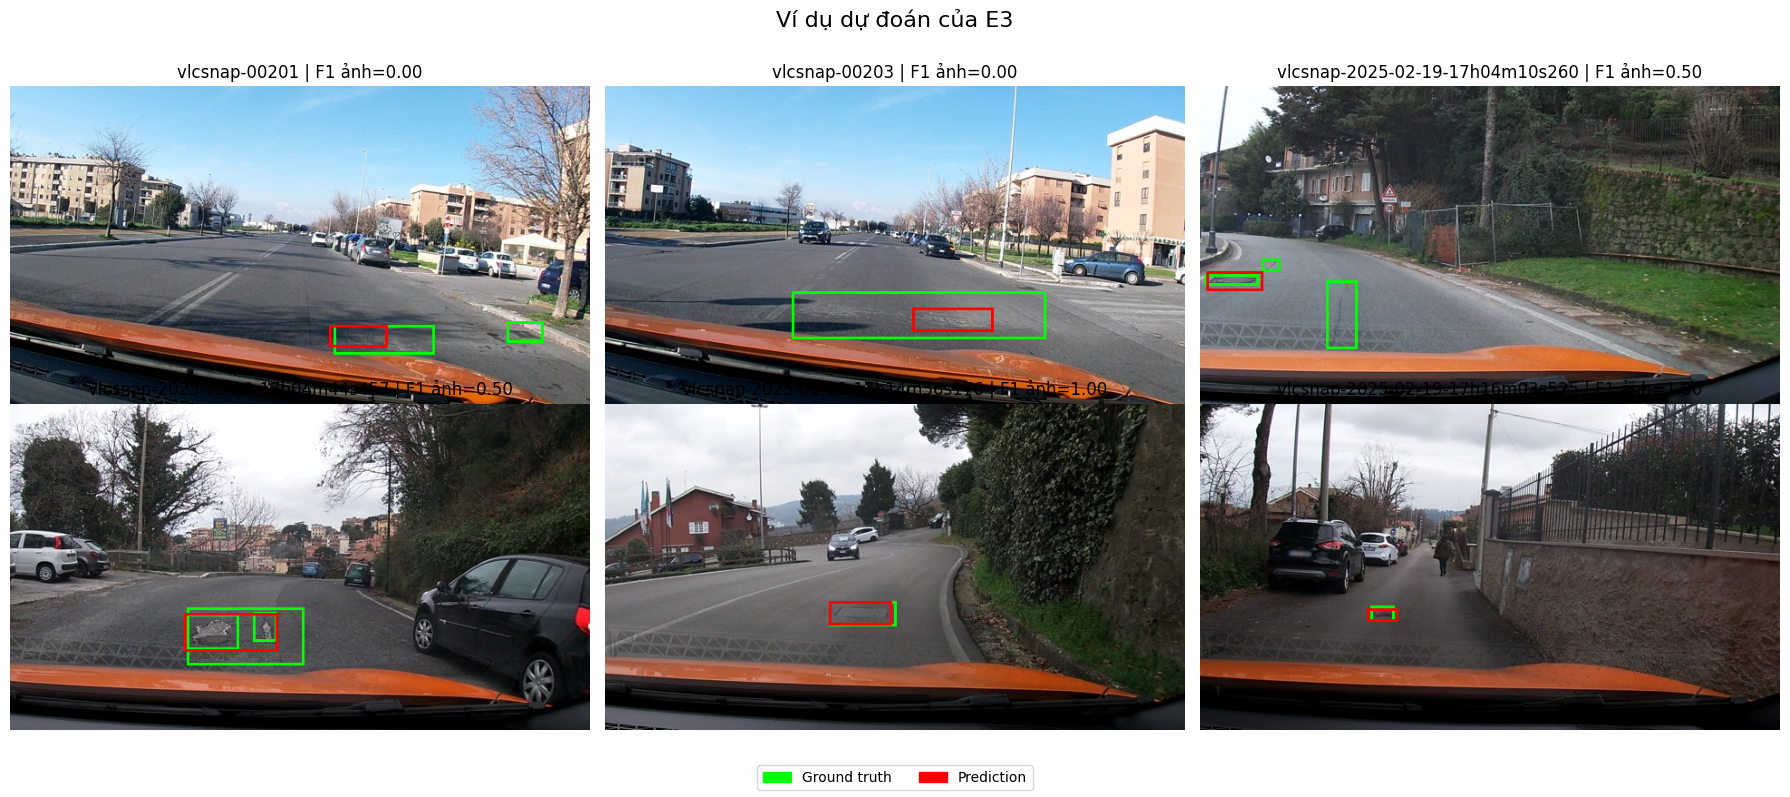

Đã lưu hình minh hoạ: report/figures/prediction_examples.png


In [16]:
# Tạo hình minh hoạ dự đoán cho REPORT.md.
from matplotlib.patches import Patch
from scripts.score import parse_output, _gt_boxes, _match, _prf

pred_rows = read_jsonl(Path("work") / f"{best_setup.lower()}.jsonl")
pred_by_id = {row["image_id"]: row["raw"] for row in pred_rows}

scored_examples = []
for item in test_records:
    parsed = parse_output(pred_by_id.get(item["image_id"], ""))
    predictions = parsed if parsed is not None else []
    per_class, _ = _match(_gt_boxes(item), predictions)
    tp = sum(v[0] for v in per_class.values())
    fp = sum(v[1] for v in per_class.values())
    fn = sum(v[2] for v in per_class.values())
    scored_examples.append((_prf(tp, fp, fn)["f1"], item, predictions))

scored_examples.sort(key=lambda row: row[0])
n_examples = len(scored_examples)
assert n_examples >= 6, "Tập test cần ít nhất 6 ảnh để tạo hình minh hoạ."
selected_indices = [0, 1, n_examples // 2, n_examples // 2 + 1, n_examples - 2, n_examples - 1]
selected = [scored_examples[i] for i in selected_indices]

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, (f1_value, item, predictions) in zip(axes.flat, selected):
    with Image.open(Path("data") / item["image_path"]) as src:
        display_img = src.convert("RGB")
    width, height = display_img.size
    draw = ImageDraw.Draw(display_img)

    for gt in _gt_boxes(item):
        x1, y1, x2, y2 = gt["bbox"]
        pixel_box = [x1 / 1000 * width, y1 / 1000 * height, x2 / 1000 * width, y2 / 1000 * height]
        draw.rectangle(pixel_box, outline="lime", width=3)
    for pred in predictions:
        x1, y1, x2, y2 = pred["bbox"]
        pixel_box = [x1 / 1000 * width, y1 / 1000 * height, x2 / 1000 * width, y2 / 1000 * height]
        draw.rectangle(pixel_box, outline="red", width=3)

    ax.imshow(display_img)
    ax.set_title(f"{item['image_id']} | F1 ảnh={f1_value:.2f}")
    ax.axis("off")
    display_img.close()

fig.legend(handles=[Patch(color="lime", label="Ground truth"), Patch(color="red", label="Prediction")], loc="lower center", ncol=2)
fig.suptitle(f"Ví dụ dự đoán của {best_setup}", fontsize=16)
fig.tight_layout(rect=[0, 0.06, 1, 0.95])
figure_path = Path("report/figures/prediction_examples.png")
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Đã lưu hình minh hoạ: {figure_path}")


In [17]:
# Kiểm tra tổng thể bài nộp trước khi hoàn tất
!python scripts/check_submission.py


[PASS] evidence e0
[PASS] evidence e1
[PASS] evidence e2
[PASS] evidence e3
[PASS] evidence e4 — 2 file
[PASS] e1 meta
[PASS] e2 meta
[PASS] e3 meta
[PASS] dataset_version nhất quán — ['d10-21e4070301']
[PASS] khớp data/splits/meta.json
[FAIL] REPORT.md đã điền — còn chuỗi '<điền'
[FAIL] git commits — 2/5
[PASS] git forbidden files

2 FAIL, 0 WARN
